# DeepTuneIO Analyzer — Contention Analysis (v6)

Visualización de coincidencias DXT con títulos descriptivos y paletas seleccionables. Las coincidencias no demuestran por sí mismas degradación.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image

# Localiza el módulo aunque Jupyter se abra desde la raíz del proyecto.
CANDIDATES = [
    Path.cwd(),
    Path.cwd() / "10_Visualization" / "Contention_Analysis",
    Path.cwd() / "Contention_Analysis",
]
ROOT = next((p.resolve() for p in CANDIDATES if (p / "Module" / "contention_pipeline.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "No encuentro Module/contention_pipeline.py. Abre el notebook desde "
        "10_Visualization/Contention_Analysis o desde la raíz DeepTuneIO."
    )
ACCESS_PATTERN_MODULE = ROOT.parent / "Access_Pattern" / "Module"
if not (ACCESS_PATTERN_MODULE / "Access_Pattern_Visualization" / "processor.py").is_file():
    raise FileNotFoundError(
        f"Falta Access_Pattern: {ACCESS_PATTERN_MODULE}. "
        "Instala ambas carpetas al mismo nivel dentro de 10_Visualization."
    )
sys.path.insert(0, str(ACCESS_PATTERN_MODULE))
sys.path.insert(0, str(ROOT / "Module"))
from contention_pipeline import run_contention
print("Contention_Analysis:", ROOT)
print("Detector Access_Pattern:", ACCESS_PATTERN_MODULE)


Contention_Analysis: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Contention_Analysis
Detector Access_Pattern: F:\NoteBooks\CORA_DR_UAB\Tesis\Scripts\DeepTuneIO\10_Visualization\Access_Pattern\Module


## Inventario de JobID y metadatos disponibles
Los campos identificados desde el nombre del archivo se etiquetan como tales. `N/D` significa no disponible.

In [5]:
# Inventario de JobID disponibles en la campaña (sin cargar todos los eventos DXT)
import re
import pandas as pd
from pathlib import Path
from IPython.display import display

CAMPAIGN_ROOT = Path(r"D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1")
APPLICATION = "DeepGalaxy"
DATASET_GROUP = "DG_bw512_f3c5x64"
SCENARIO = "nfs_SnGPU_e1"
FILE_FORMAT = "hdf5"

analysis_root = CAMPAIGN_ROOT / "results" / "Access_Pattern_DXT" / "Analysis"
if not analysis_root.is_dir():
    print(f"No existe el directorio de análisis DXT: {analysis_root}")
    JOB_INVENTORY = pd.DataFrame()
else:
    records = []
    for path in sorted(analysis_root.rglob("*_dxt_analysis.csv")):
        stem = path.stem
        # JobID: último número largo anterior a sufijos de instrumentación, cuando existe.
        matches = re.findall(r"(?<!\d)(\d{6,})(?!\d)", stem)
        if not matches:
            continue
        job_id = int(matches[-1])
        name = path.name.lower()
        def match(pattern):
            m = re.search(pattern, name, flags=re.I)
            return m.group(1) if m else None
        nodes = match(r"_n(\d+)p\d+")
        procs = match(r"_n\d+p(\d+)")
        epochs = match(r"_n\d+p\d+e(\d+)")
        mode_code = match(r"_(m[01])(?:_|\.)")
        access_mode = {"m0": "Shared", "m1": "Shared + Reload + Shuffle"}.get(mode_code.lower()) if mode_code else None
        fmt = next((f.upper() for f in ("hdf5", "tfrecord", "npz", "jpeg") if f in name), None)
        # N/D evita interpretar nombres ambiguos como metadatos confirmados.
        records.append({
            "JobID": job_id, "Application": APPLICATION,
            "Dataset": DATASET_GROUP, "Filesystem": "NFS" if SCENARIO.lower().startswith("nfs") else ("Lustre" if "lustre" in SCENARIO.lower() else "N/D"),
            "Scenario": SCENARIO, "Format": fmt or "N/D",
            "Access mode (filename)": access_mode or "N/D",
            "Nodes (filename)": int(nodes) if nodes else "N/D",
            "Processes (filename)": int(procs) if procs else "N/D",
            "Epochs (filename)": int(epochs) if epochs else "N/D",
            "Batch size": "N/D", "Transfer size": "N/D", "Chunking": "N/D",
            "DXT analysis CSV": str(path),
        })
    JOB_INVENTORY = pd.DataFrame.from_records(records)
    if not JOB_INVENTORY.empty:
        JOB_INVENTORY = JOB_INVENTORY.sort_values(["JobID", "DXT analysis CSV"]).reset_index(drop=True)
        display(JOB_INVENTORY.drop(columns=["DXT analysis CSV"]))
        print(f"{JOB_INVENTORY['JobID'].nunique()} JobID únicos; {len(JOB_INVENTORY)} archivos DXT.")
    else:
        print("No se encontraron CSV de análisis DXT con JobID identificable.")
# Exportación opcional del inventario
# JOB_INVENTORY.to_csv(CAMPAIGN_ROOT / "results" / "contention_job_inventory.csv", index=False)


,JobID,Application,Dataset,Filesystem,Scenario,Format,Access mode (filename),Nodes (filename),Processes (filename),Epochs (filename),Batch size,Transfer size,Chunking
0,4942237,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared,1,4,1,N/D,N/D,N/D
1,4948089,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared + Reload + Shuffle,1,4,1,N/D,N/D,N/D
2,4998168,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared,2,8,1,N/D,N/D,N/D
3,5006144,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared,12,48,1,N/D,N/D,N/D
4,5124492,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared + Reload + Shuffle,2,8,1,N/D,N/D,N/D
5,5136376,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared + Reload + Shuffle,2,8,1,N/D,N/D,N/D
6,5169046,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared,12,48,1,N/D,N/D,N/D
7,5172871,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared + Reload + Shuffle,12,48,1,N/D,N/D,N/D
8,5173308,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared,8,32,1,N/D,N/D,N/D
9,5175899,DeepGalaxy,DG_bw512_f3c5x64,NFS,nfs_SnGPU_e1,HDF5,Shared,1,4,1,N/D,N/D,N/D


25 JobID únicos; 25 archivos DXT.


## Configuración
Selecciona una campaña y un JobID con eventos DXT. El módulo localiza los CSV de eventos automáticamente en `CAMPAIGN_ROOT/results`.


In [6]:

JOBID = 5333326  #5333197
OPERATION = "read"       # read, write, all
CASE = "AB"              # AB, A_exact, B_partial, C_shared_resource
PROCESS = None           # None = todos los procesos
FILE = None              # None = un mapa por archivo
TIME_BINS = 50
OFFSET_BINS = 40
RESOURCE_MODE = "auto"   # auto, ost, nfs, none
OUTPUT_DIR = None        # Por defecto, en results/Figures/Contention_Analysis/job_<JobID>

# Paleta aplicable a ambos mapas. Opciones: Blues, viridis, cividis, YlOrRd, magma, plasma, PuBuGn, turbo
PALETTE = "viridis"
LOG_SCALE = True  # False = escala lineal

# Mapa Proceso × Offset: volume (volumen acumulado) o mean_size (tamaño medio)
PROCESS_OFFSET_METRIC = "volume"
MAX_PAIRS = 900000  # evita truncar los 226668 pares observados en este JobID


Eventos DXT: 4193981
Pares detectados: 228239
Casos: {'A_exact': 31508, 'C_shared_resource': 196536, 'B_partial': 195}
Truncado: False
Fuentes:
 - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Access_Pattern_DXT\Analysis\25_DG_N16p64e1_EfficientNetB4_outputbw512hdf5_ds36nc14_M1_nfs_5333326_FT3RESDT_dxt_analysis.csv
Resultados: D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333326
Figuras generadas: 3
  - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333326\01_offset_time_AB_Pall_01.png | existe: True
  - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Contention_Analysis\job_5333326\03_process_offset_volume_AB_Pall_01.png | existe: True
  - D:\DL_Experiments\CORA_DR_UAB\Tesis\Data\DeepGalaxy\DG_bw512_f3c5x64\nfs_SnGPU_e1\results\Figures\Conten

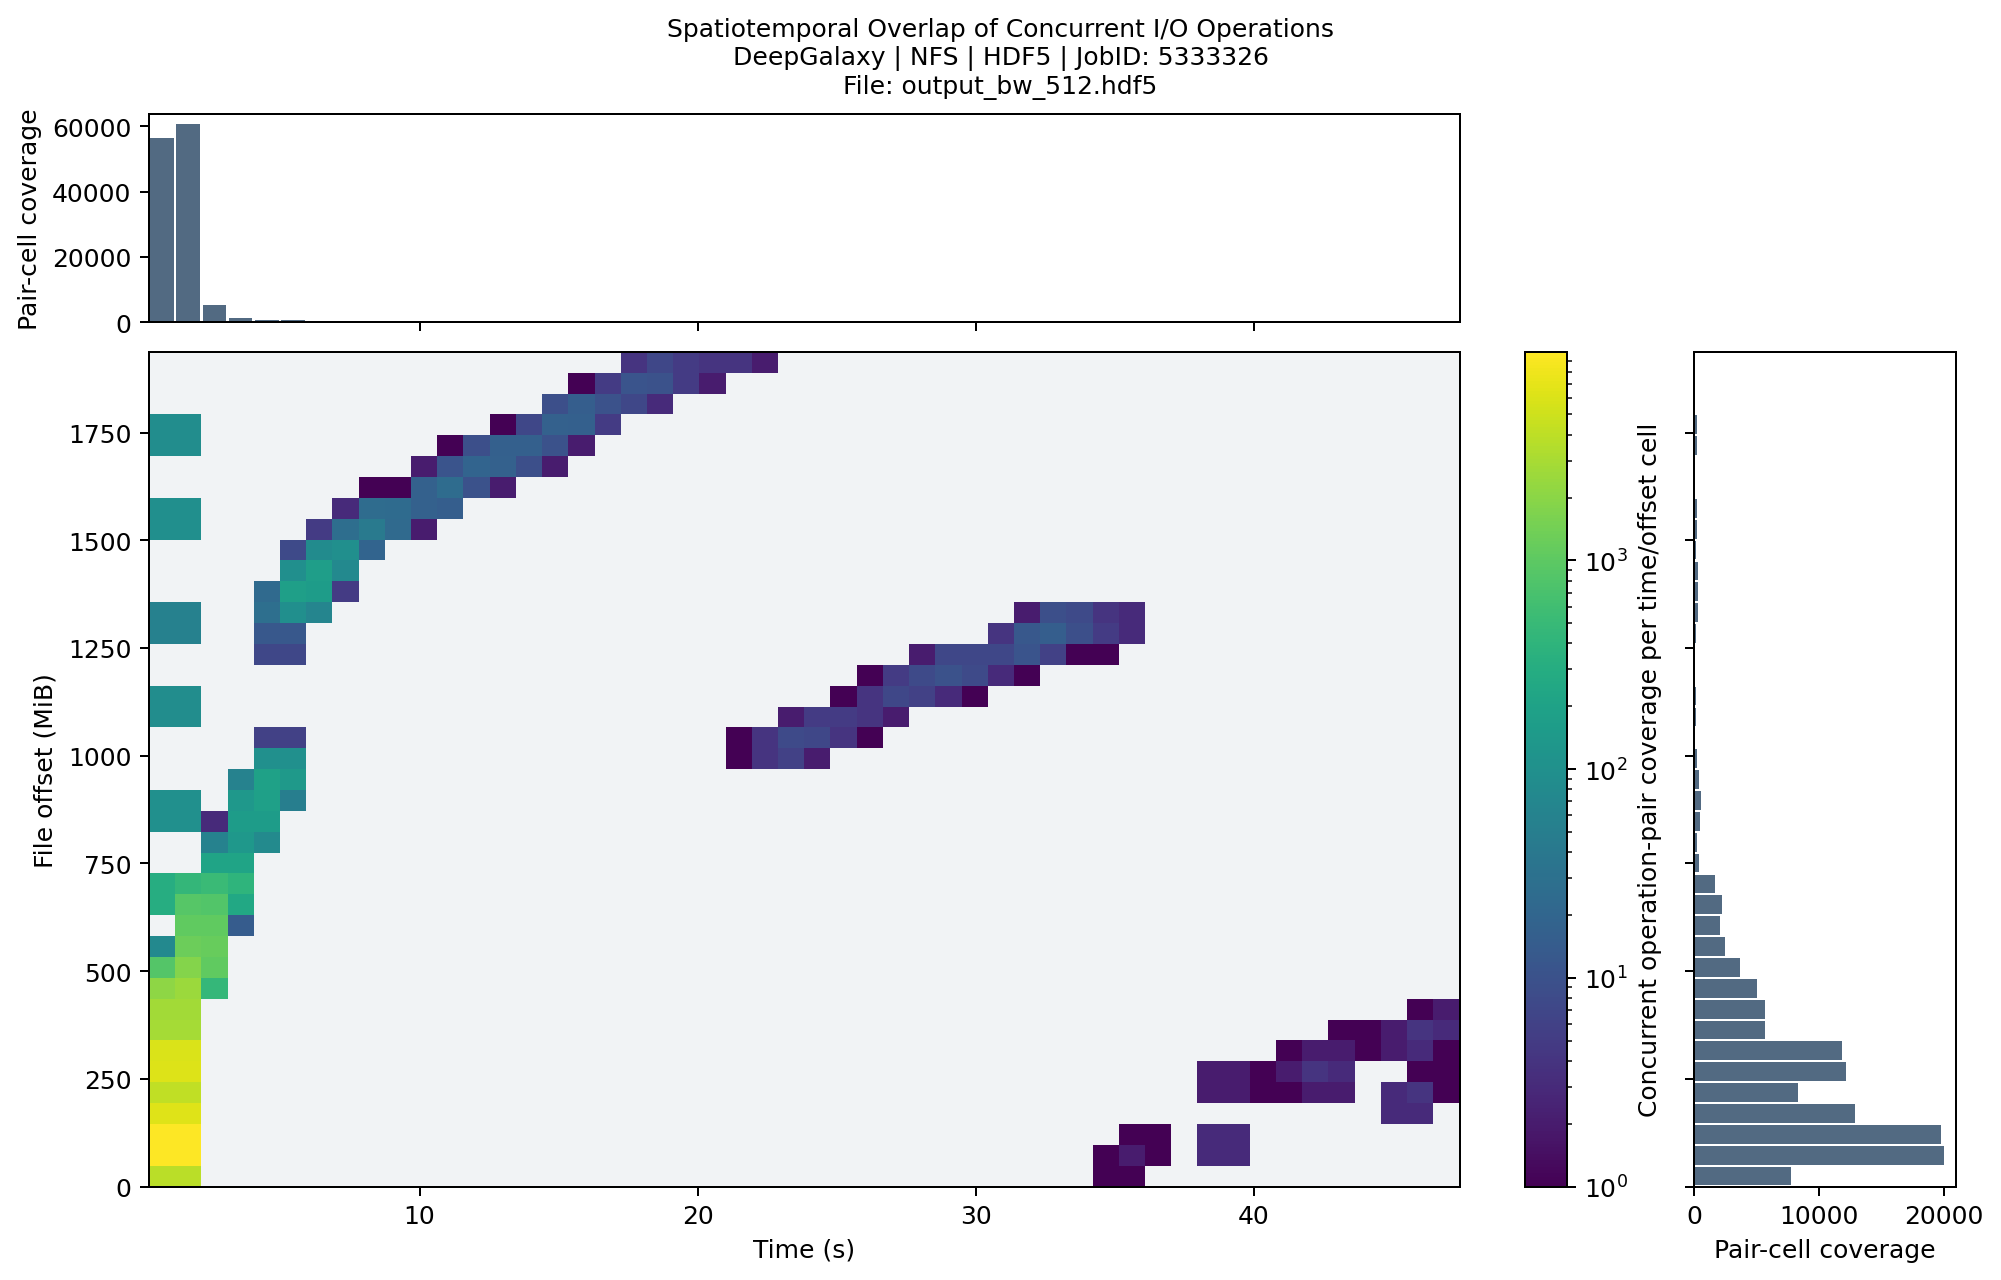

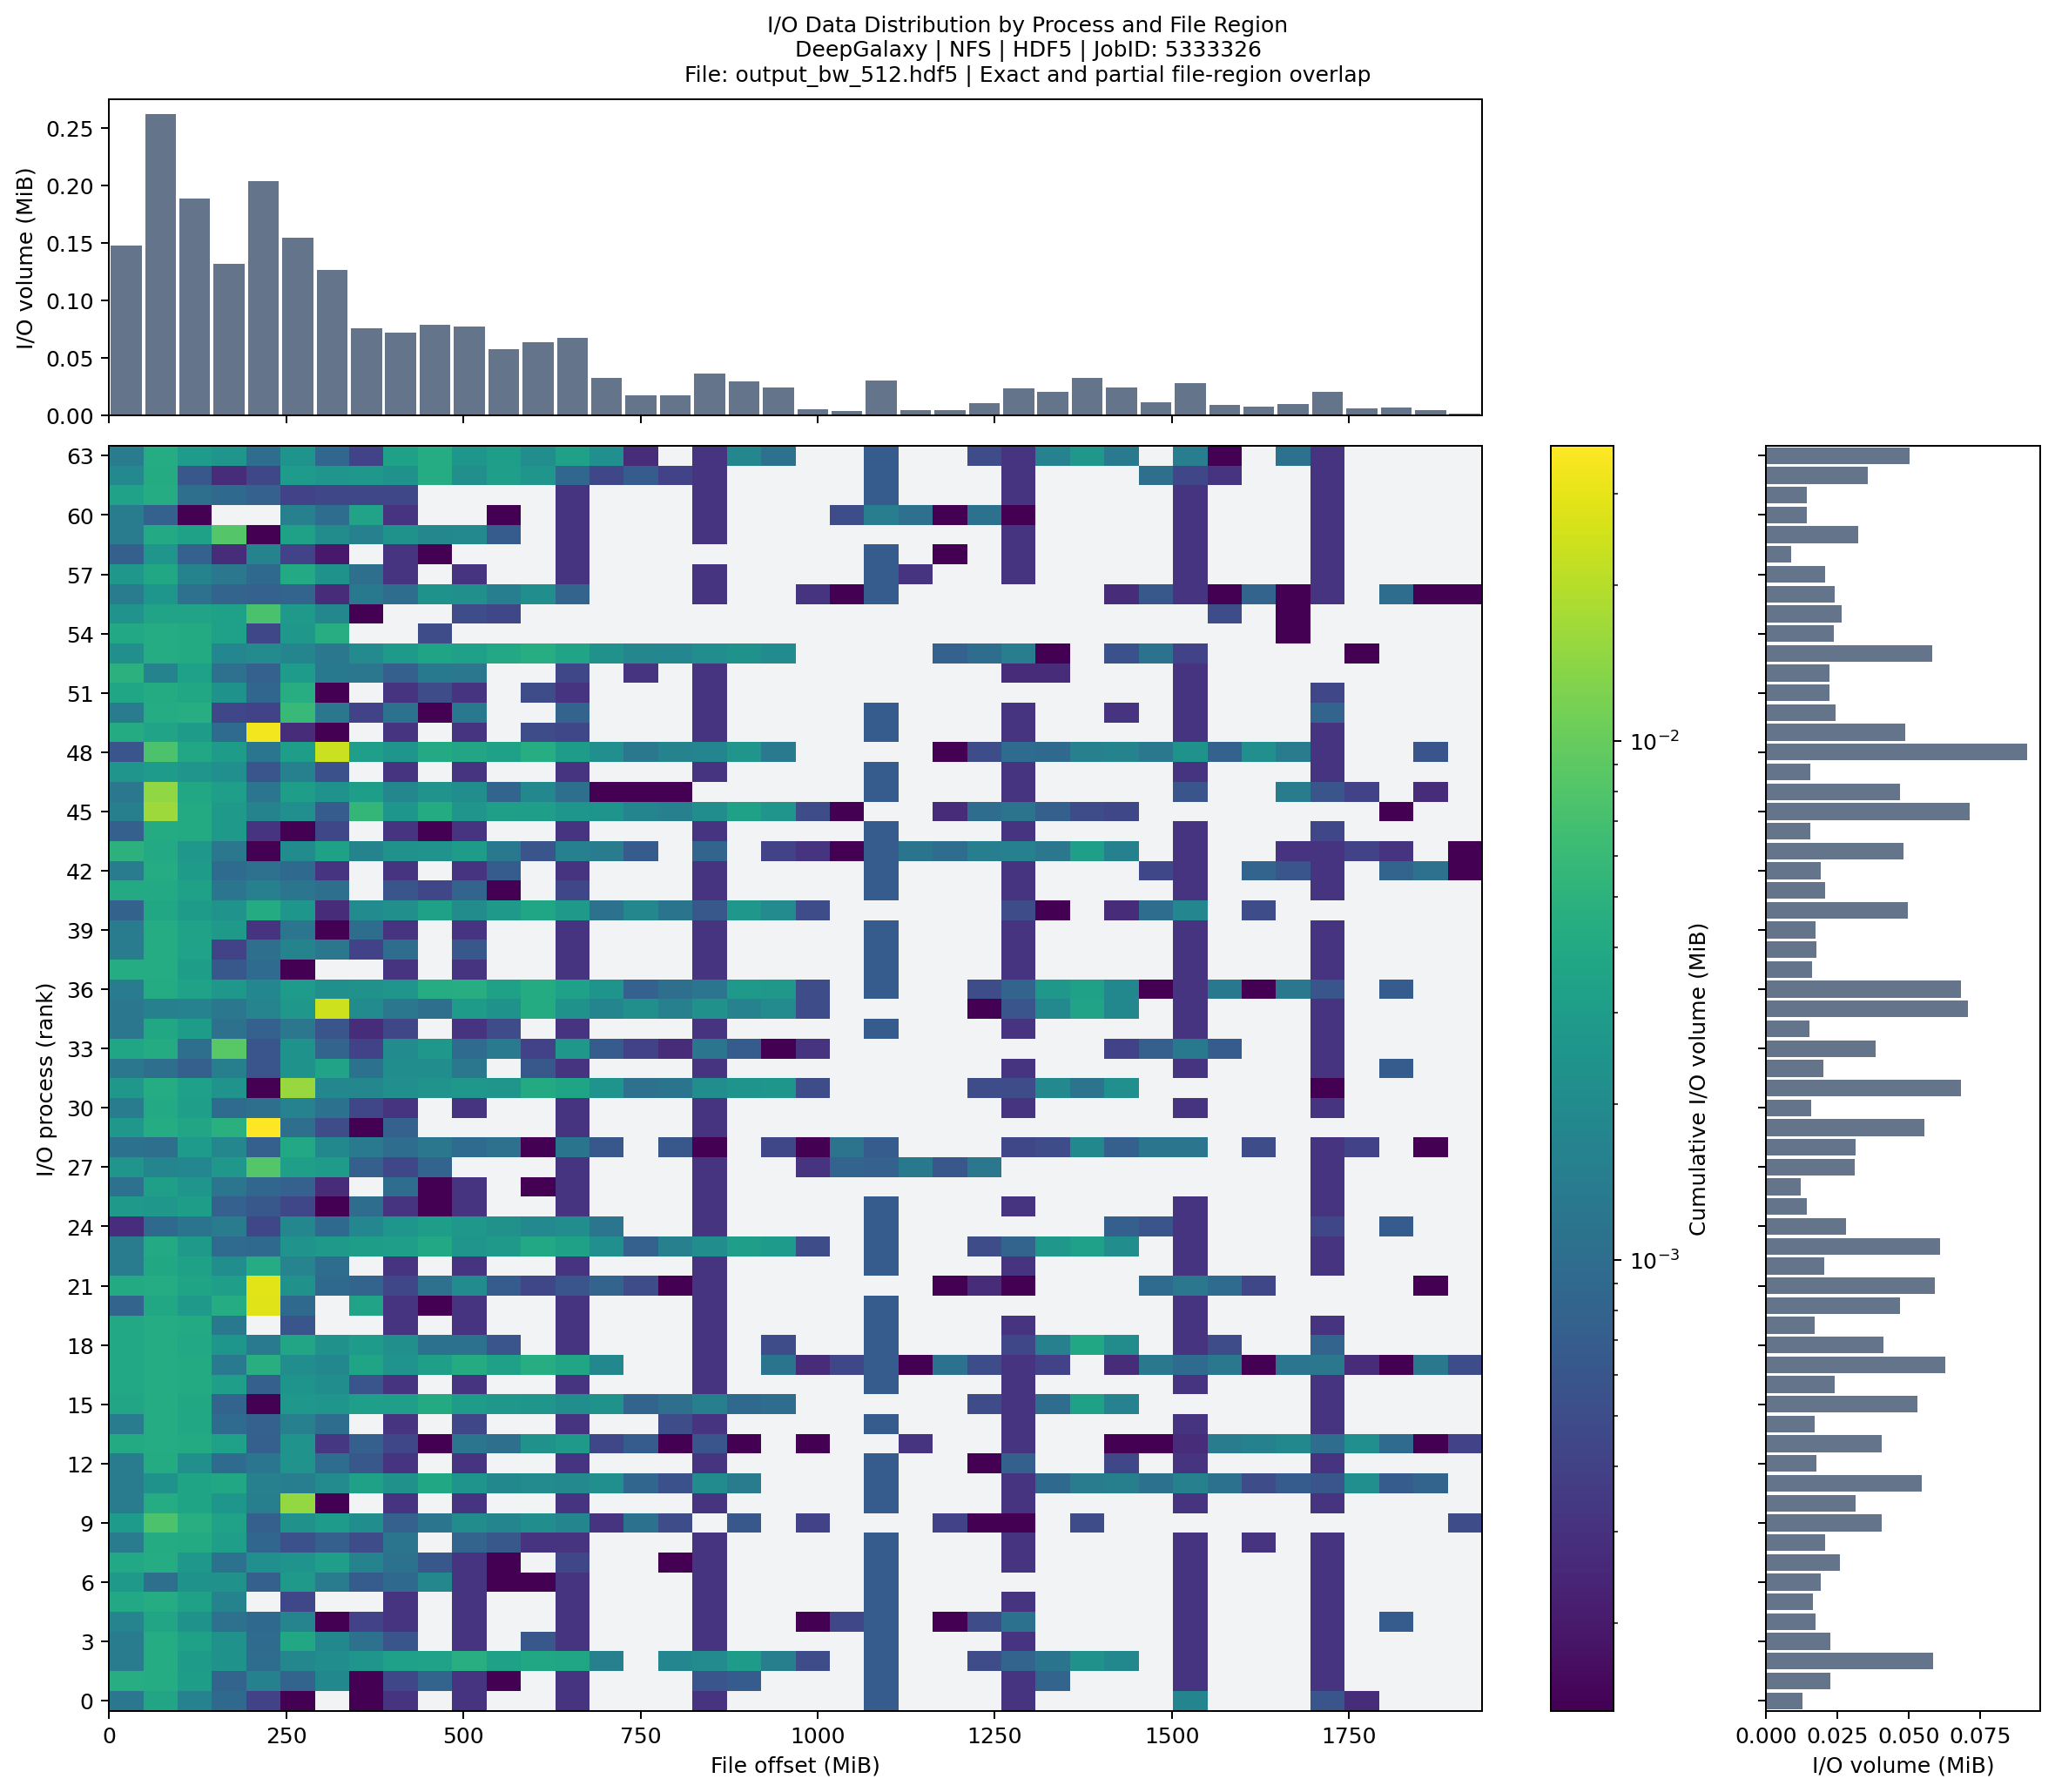

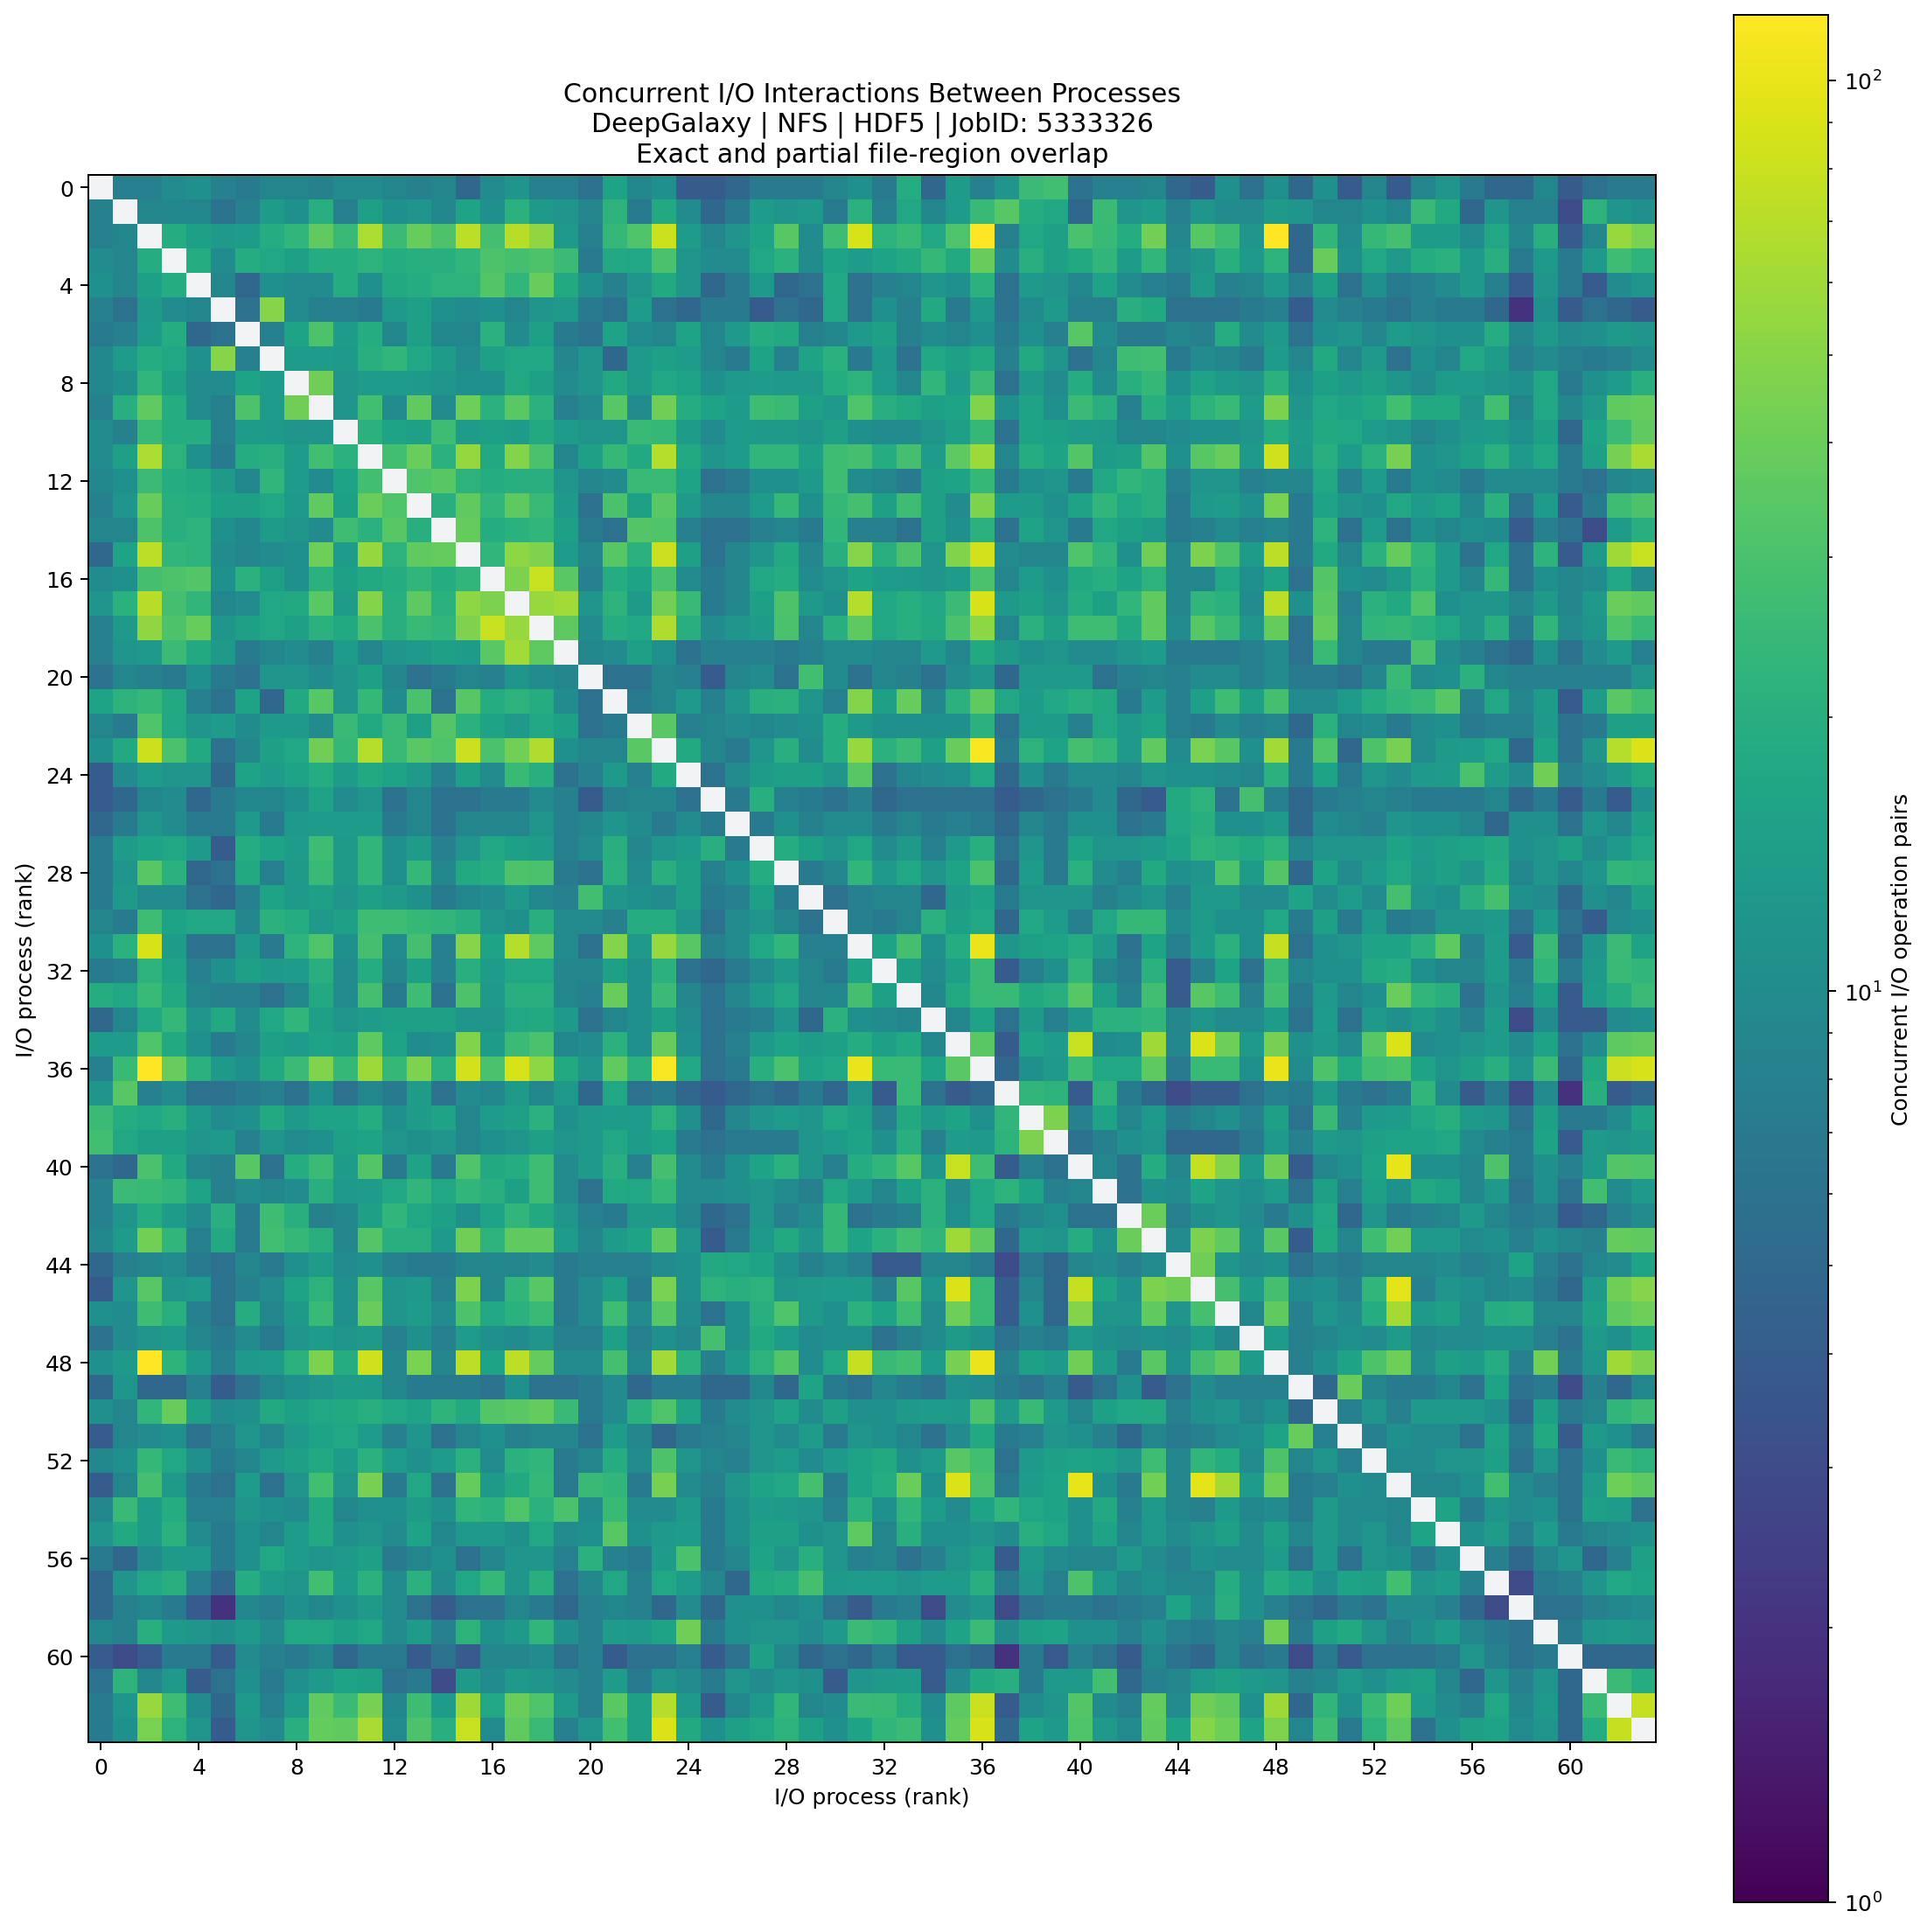

In [7]:
result = run_contention(
    campaign_root=CAMPAIGN_ROOT, application=APPLICATION,
    dataset_group=DATASET_GROUP, scenario=SCENARIO, file_format=FILE_FORMAT,
    job_id=JOBID, operation=OPERATION, case=CASE, process=PROCESS, file=FILE,
    time_bins=TIME_BINS, offset_bins=OFFSET_BINS, max_pairs=MAX_PAIRS,
    resource_mode=RESOURCE_MODE, output_dir=OUTPUT_DIR,
    palette=PALETTE, log_scale=LOG_SCALE,
    process_offset_metric=PROCESS_OFFSET_METRIC,
)
print("Eventos DXT:", result["event_count"])
print("Pares detectados:", result["pair_count"])
print("Casos:", result["diagnostics"].get("cases"))
print("Truncado:", result["diagnostics"].get("truncated"))
print("Fuentes:", *result["source_files"], sep="\n - ")
print("Resultados:", result["output_dir"])
if result["diagnostics"].get("truncated"):
    print("ADVERTENCIA: el detector alcanzó MAX_PAIRS; resultados parciales.")
print("Figuras generadas:", len(result["figures"]))
for figure in result["figures"]:
    print("  -", figure, "| existe:", figure.is_file())
print("Archivos PNG presentes en la carpeta:")
for png in sorted(result["output_dir"].glob("*.png")):
    print("  -", png.name)

if not result["figures"]:
    print("Sin figuras para el filtro seleccionado: comprueba CASE, PROCESS y FILE.")
for fig in result["figures"]:
    display(Image(filename=str(fig)))
